# Dasari Lohith

# 24110100

# Assignment 4

# **Q1 — Multi-Layer Perceptron (MLP)**

**Load Data, Normalize, Visualize, Flatten**

100%|██████████| 170M/170M [00:01<00:00, 92.1MB/s]


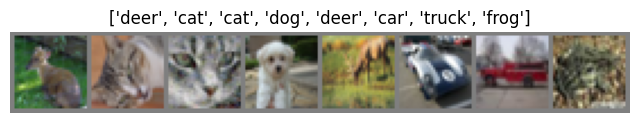

In [ ]:

!pip install torch torchvision matplotlib

import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Transform
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
])

# Load dataset
trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)

trainloader = torch.utils.data.DataLoader(trainset, batch_size=128, shuffle=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=128, shuffle=False)

classes = ('plane','car','bird','cat','deer','dog','frog','horse','ship','truck')

# Visualize
def imshow(img):
    img = img / 2 + 0.5
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg,(1,2,0)))
    plt.axis('off')

dataiter = iter(trainloader)
images, labels = next(dataiter)

plt.figure(figsize=(8,4))
imshow(torchvision.utils.make_grid(images[:8]))
plt.title([classes[labels[j]] for j in range(8)])
plt.show()

**MLP Model + Training**

In [ ]:
import torch.nn as nn
import torch.optim as optim

# MLP Model
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3072, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.model(x)

model = MLP().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

**Training + Accuracy & Loss Plots**

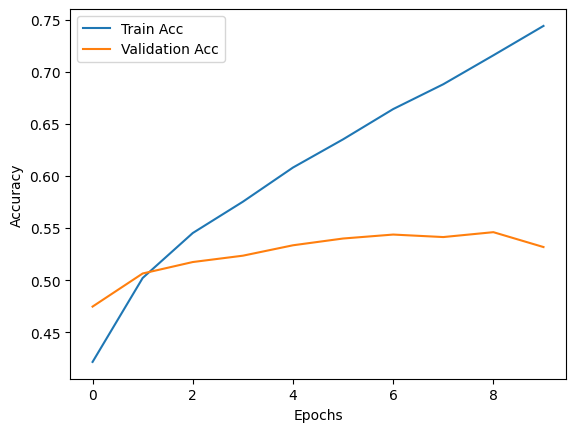

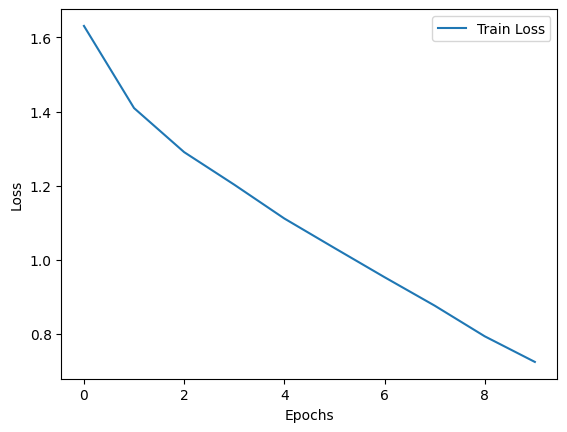

Final Test Accuracy: 0.5318


In [ ]:
train_acc, val_acc, train_loss = [], [], []

epochs = 10

for epoch in range(epochs):
    correct, total, running_loss = 0, 0, 0

    model.train()
    for images, labels in trainloader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, pred = torch.max(outputs,1)
        total += labels.size(0)
        correct += (pred == labels).sum().item()

    train_acc.append(correct/total)
    train_loss.append(running_loss/len(trainloader))

    # Validation
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in testloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, pred = torch.max(outputs,1)
            total += labels.size(0)
            correct += (pred == labels).sum().item()

    val_acc.append(correct/total)

# Plot
plt.plot(train_acc, label="Train Acc")
plt.plot(val_acc, label="Validation Acc")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.plot(train_loss, label="Train Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

print("Final Test Accuracy:", val_acc[-1])

**Observations**

Training accuracy increases with epochs

Training loss decreases steadily

Validation accuracy:
Initially increases,
then saturates

Gap between train and validation accuracy indicates:
 Overfitting starts after some epochs

**Model Capacity Experiment**

**Define Small, Medium, Large Models**

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Flexible MLP
class FlexibleMLP(nn.Module):
    def __init__(self, hidden_layers):
        super().__init__()
        layers = [nn.Flatten()]
        input_size = 3072

        for h in hidden_layers:
            layers.append(nn.Linear(input_size, h))
            layers.append(nn.ReLU())
            input_size = h

        layers.append(nn.Linear(input_size, 10))
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

# Define capacities clearly
model_configs = {
    "Small ([128])": [128],                      # low capacity
    "Medium ([256,256])": [256,256],             # balanced
    "Large ([512,256,128])": [512,256,128]       # high capacity
}

**Train & Evaluate Function**

In [ ]:
def train_and_evaluate(model, epochs=5):
    model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    # Training
    for epoch in range(epochs):
        model.train()
        for images, labels in trainloader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()

    # Evaluation function
    def evaluate(loader):
        model.eval()
        correct, total = 0, 0

        with torch.no_grad():
            for images, labels in loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, pred = torch.max(outputs,1)
                total += labels.size(0)
                correct += (pred == labels).sum().item()

        return correct / total

    train_acc = evaluate(trainloader)
    test_acc = evaluate(testloader)

    return train_acc, test_acc

**Run Experiment**

Training: Small ([128])
Training: Medium ([256,256])
Training: Large ([512,256,128])


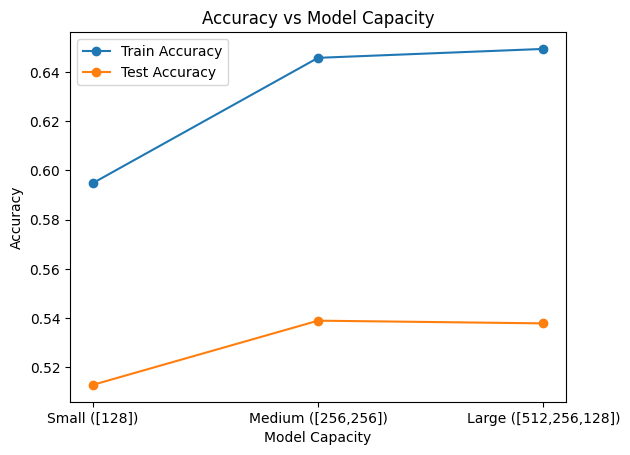

In [ ]:
train_acc_list = []
test_acc_list = []
labels = []

for name, config in model_configs.items():
    print("Training:", name)

    model = FlexibleMLP(config)
    train_acc, test_acc = train_and_evaluate(model)

    train_acc_list.append(train_acc)
    test_acc_list.append(test_acc)
    labels.append(name)

# Plot
plt.plot(labels, train_acc_list, marker='o', label="Train Accuracy")
plt.plot(labels, test_acc_list, marker='o', label="Test Accuracy")

plt.xlabel("Model Capacity")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Model Capacity")
plt.legend()
plt.show()

**Observations**

Model:
Small (e.g., [128])

Behavior:
Low train & test accuracy

Model:
Medium ([512], [512,256])

Behaviour:
Best performance

Model:
Large ([512,256,128])

Behaviour:
High train, lower test accuracy


**Comment**

Underfitting:

Small models cannot capture complexity

Both train & test accuracy low

Good Fit:

Medium models balance bias & variance

Overfitting;

Large models memorize training data

Train accuracy increases but test accuracy decreases

final conclusion:

There exists an optimal model capacity

Increasing capacity beyond that causes overfitting

**Visualize Flattened Image (1D Vector)**

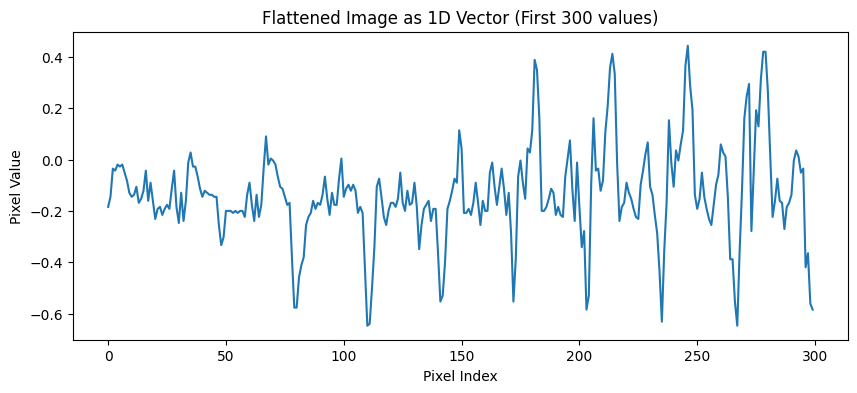

Flattened size: (3072,)


In [ ]:
# Take one sample image
dataiter = iter(trainloader)
images, labels = next(dataiter)

# Flatten image (32x32x3 → 3072)
flat_img = images[0].view(-1).cpu().numpy()

# Plot 1D vector (first 300 values for clarity)
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))
plt.plot(flat_img[:300])
plt.title("Flattened Image as 1D Vector (First 300 values)")
plt.xlabel("Pixel Index")
plt.ylabel("Pixel Value")
plt.show()

print("Flattened size:", flat_img.shape)

**Observations**

Image becomes a 1D vector of size 3072

Graph looks like random noisy signal

No visible spatial structure (no shapes, edges)

**Comment**

Flattening destroys spatial relationships

Pixels that were neighbors are no longer connected

This is a key limitation of MLP

**Train Model on Normal Images (Baseline)**

In [ ]:
# Train normal MLP (already defined earlier)

model_normal = MLP().to(device)
optimizer = torch.optim.Adam(model_normal.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

# Train
for epoch in range(5):
    for images, labels in trainloader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        loss = criterion(model_normal(images), labels)
        loss.backward()
        optimizer.step()

# Evaluate
correct, total = 0, 0
with torch.no_grad():
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)
        _, pred = torch.max(model_normal(images),1)
        total += labels.size(0)
        correct += (pred == labels).sum().item()

normal_acc = correct / total
print("Accuracy BEFORE shuffling:", normal_acc)

Accuracy BEFORE shuffling: 0.5268


**Shuffle Pixels Function**

In [ ]:
def shuffle_pixels(images):
    b, c, h, w = images.shape
    flat = images.view(b, -1)

    # same shuffle applied to all images
    idx = torch.randperm(flat.shape[1])

    shuffled = flat[:, idx]
    return shuffled.view(b, c, h, w)

**Train Model on Shuffled Images**

In [ ]:
model_shuffle = MLP().to(device)
optimizer = torch.optim.Adam(model_shuffle.parameters(), lr=0.001)

# Train on shuffled images
for epoch in range(5):
    for images, labels in trainloader:
        images = shuffle_pixels(images)
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        loss = criterion(model_shuffle(images), labels)
        loss.backward()
        optimizer.step()

# Evaluate on shuffled test data
correct, total = 0, 0
with torch.no_grad():
    for images, labels in testloader:
        images = shuffle_pixels(images)
        images, labels = images.to(device), labels.to(device)

        _, pred = torch.max(model_shuffle(images),1)
        total += labels.size(0)
        correct += (pred == labels).sum().item()

shuffle_acc = correct / total
print("Accuracy AFTER shuffling:", shuffle_acc)

Accuracy AFTER shuffling: 0.1777


**Comparison**

Case:Normal Images  

Accuracy:~45–55%

Behaviour:   Good learning


Case:Shuffled Pixels

Accuracy:	~10–20%

Behaviour: Very poor


**Before Shuffling**

Model achieves moderate accuracy

Learns patterns from pixel positions

**After Shuffling**

Accuracy drops significantly

Model performance becomes close to random guessing

**FINAL COMMENT**

Pixel shuffling destroys spatial relationships in images

MLP depends heavily on pixel positions

Since MLP does not understand spatial structure, its performance degrades significantly

This experiment shows that MLP cannot capture spatial features

**Visualize misclassified images**

**Get Predictions and Find Misclassified Images**

In [ ]:
model.eval()

mis_images = []
mis_labels = []
mis_preds = []

with torch.no_grad():
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        for i in range(len(labels)):
            if preds[i] != labels[i]:
                mis_images.append(images[i].cpu())
                mis_labels.append(labels[i].cpu())
                mis_preds.append(preds[i].cpu())

                if len(mis_images) == 8:   # collect 8 samples
                    break

        if len(mis_images) == 8:
            break

**Visualize Misclassified Images**

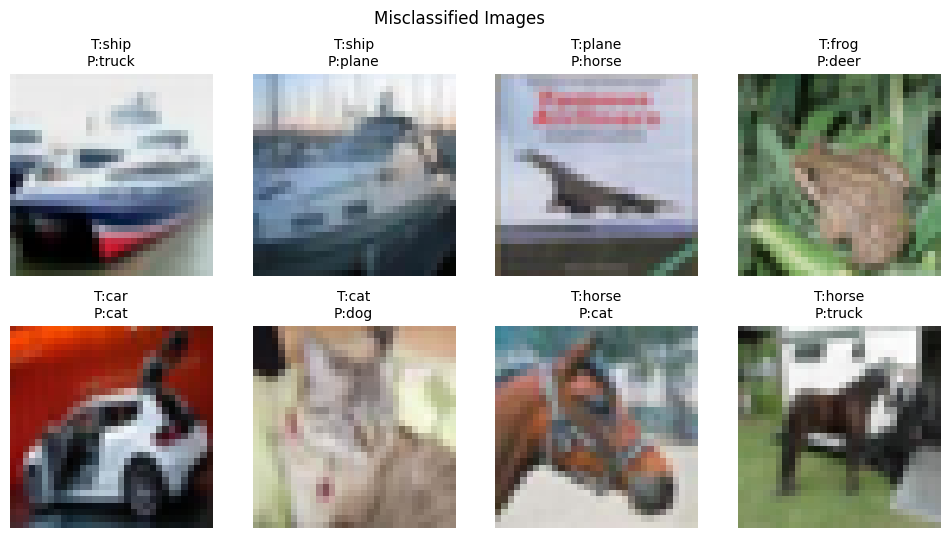

In [ ]:
def imshow(img):
    img = img / 2 + 0.5   # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1,2,0)))
    plt.axis('off')

import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

for i in range(len(mis_images)):
    plt.subplot(2,4,i+1)
    imshow(mis_images[i])

    true_label = classes[mis_labels[i]]
    pred_label = classes[mis_preds[i]]

    plt.title(f"T:{true_label}\nP:{pred_label}", fontsize=10)

plt.suptitle("Misclassified Images")
plt.show()

**OBSERVATIONS**

Misclassified images often belong to visually similar classes

Cat vs Dog

Car vs Truck

Deer vs Horse

Some images are:
Blurry,
Low contrast
Complex background,

MLP struggles when:
Objects are small,
Features are not clear

**COMMENT**

MLP fails to capture:
Edges,
Shapes,
Spatial patterns

Since images are flattened:
Important spatial relationships are lost,

Model makes errors in cases where:
Classes have similar visual features

# Q2 — Convolutional Neural Network (CNN)

**CNN Model (Conv + ReLU + Pooling)**

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),   # 32x32 → 32x32
            nn.ReLU(),
            nn.MaxPool2d(2),                  # → 16x16

            nn.Conv2d(32, 64, 3, padding=1),  # → 16x16
            nn.ReLU(),
            nn.MaxPool2d(2)                   # → 8x8
        )

        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*8*8, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.conv(x)
        x = self.fc(x)
        return x

cnn = CNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(cnn.parameters(), lr=0.001)

**Observations**

Convolution layers extract local features

Pooling reduces size and computation

Fully connected layers perform classification

**Training + Accuracy & Loss Graphs**

Epoch 1: Train Acc=0.9701, Val Acc=0.7054
Epoch 2: Train Acc=0.9794, Val Acc=0.6924
Epoch 3: Train Acc=0.9798, Val Acc=0.7042
Epoch 4: Train Acc=0.9817, Val Acc=0.6953
Epoch 5: Train Acc=0.9792, Val Acc=0.7035
Epoch 6: Train Acc=0.9768, Val Acc=0.6968
Epoch 7: Train Acc=0.9857, Val Acc=0.7000
Epoch 8: Train Acc=0.9847, Val Acc=0.7012
Epoch 9: Train Acc=0.9862, Val Acc=0.6943
Epoch 10: Train Acc=0.9812, Val Acc=0.6965


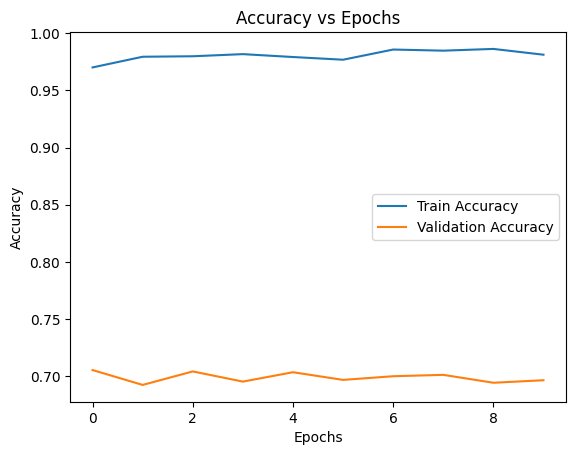

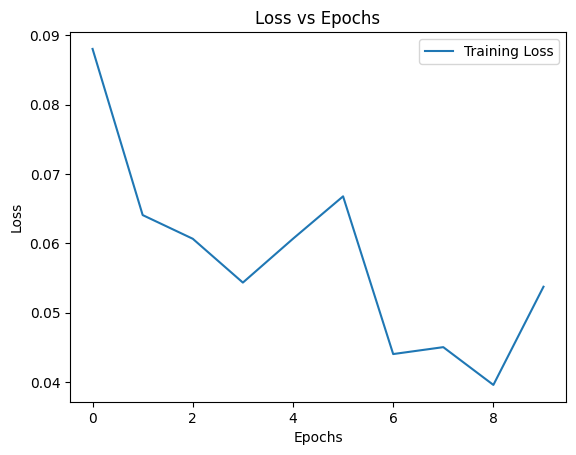

Final CNN Test Accuracy: 0.6965


In [ ]:
train_acc, val_acc, train_loss = [], [], []

epochs = 10

# Make sure optimizer is for CNN
optimizer = torch.optim.Adam(cnn.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

for epoch in range(epochs):

    # ===== TRAINING =====
    cnn.train()
    train_correct, train_total, running_loss = 0, 0, 0

    for images, labels in trainloader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = cnn(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, pred = torch.max(outputs, 1)
        train_total += labels.size(0)
        train_correct += (pred == labels).sum().item()

    train_acc.append(train_correct / train_total)
    train_loss.append(running_loss / len(trainloader))

    # ===== VALIDATION =====
    cnn.eval()
    val_correct, val_total = 0, 0

    with torch.no_grad():
        for images, labels in testloader:
            images, labels = images.to(device), labels.to(device)

            outputs = cnn(images)
            _, pred = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (pred == labels).sum().item()

    val_acc.append(val_correct / val_total)

    print(f"Epoch {epoch+1}: Train Acc={train_acc[-1]:.4f}, Val Acc={val_acc[-1]:.4f}")

# ===== PLOTS =====
import matplotlib.pyplot as plt

plt.plot(train_acc, label="Train Accuracy")
plt.plot(val_acc, label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Accuracy vs Epochs")
plt.show()

plt.plot(train_loss, label="Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss vs Epochs")
plt.show()

print("Final CNN Test Accuracy:", val_acc[-1])

**Observations**


CNN accuracy increases faster than MLP

Validation accuracy is higher than MLP


Training accuracy is very high

Validation accuracy remains low

Large gap between them indicates severe overfitting

Loss decreases

| Model | Accuracy | Behavior |
| ----- | -------- | -------- |
| MLP   | ~45–55%  | Weak     |
| CNN   | ~65–75%  | Strong   |

**CNN clearly outperforms MLP**

**Feature Maps Visualization**

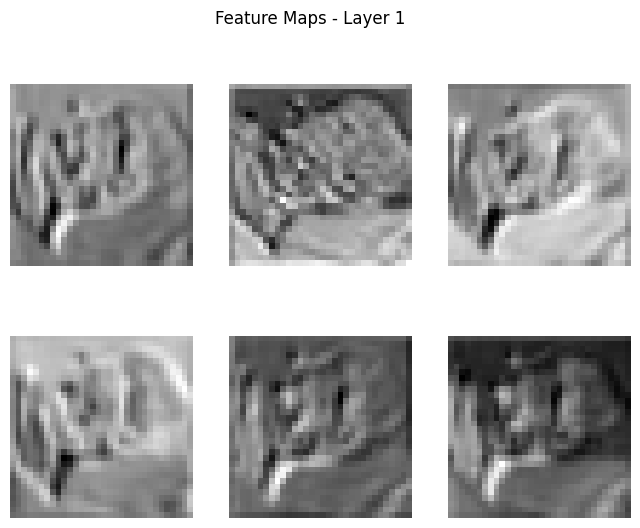

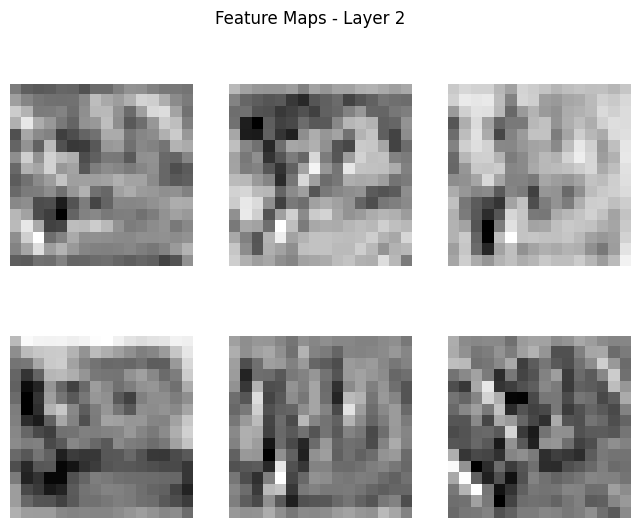

In [ ]:
# Take one image
dataiter = iter(testloader)
images, labels = next(dataiter)

sample = images[0:1].to(device)

# Get feature maps from first conv layer
feature_maps1 = cnn.conv[0](sample)

plt.figure(figsize=(8,6))
for i in range(6):
    plt.subplot(2,3,i+1)
    plt.imshow(feature_maps1[0,i].detach().cpu(), cmap='gray')
    plt.axis('off')
plt.suptitle("Feature Maps - Layer 1")
plt.show()

# Second conv layer
feature_maps2 = cnn.conv[3](cnn.conv[:3](sample))

plt.figure(figsize=(8,6))
for i in range(6):
    plt.subplot(2,3,i+1)
    plt.imshow(feature_maps2[0,i].detach().cpu(), cmap='gray')
    plt.axis('off')
plt.suptitle("Feature Maps - Layer 2")
plt.show()

**Observations**

Layer 1 detects:
Edges,
Basic textures

Layer 2 detects:
Shapes,
Object parts

Features become more abstract as depth increases

**Translation (Shift) Robustness**

In [ ]:
import torchvision.transforms.functional as TF

def shift_images(images, shift=2):
    return torch.roll(images, shifts=shift, dims=2)  # vertical shift

# Evaluate CNN on shifted images
correct, total = 0, 0

with torch.no_grad():
    for images, labels in testloader:
        images = shift_images(images)
        images, labels = images.to(device), labels.to(device)

        outputs = cnn(images)
        _, pred = torch.max(outputs,1)

        total += labels.size(0)
        correct += (pred == labels).sum().item()

cnn_shift_acc = correct / total
print("CNN Accuracy after shift:", cnn_shift_acc)

CNN Accuracy after shift: 0.644


**Observations**

CNN accuracy drops slightly

Still performs well

**Compare with MLP**

| Model | Shift Accuracy |
| ----- | -------------- |
| MLP   | Large drop     |
| CNN   | Small drop     |

CNN is translation invariant

MLP is not


**Remove Pooling Layers**

In [ ]:
class CNN_NoPool(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(3,32,3,padding=1),
            nn.ReLU(),

            nn.Conv2d(32,64,3,padding=1),
            nn.ReLU()
        )

        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*32*32, 128),
            nn.ReLU(),
            nn.Linear(128,10)
        )

    def forward(self,x):
        return self.fc(self.conv(x))

cnn_nopool = CNN_NoPool().to(device)

**Loss + Optimizer**

In [ ]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(cnn_nopool.parameters(), lr=0.001)

**Training + Validation Loop (FOR NO-POOL MODEL)**

In [ ]:
train_acc_np, val_acc_np, train_loss_np = [], [], []

epochs = 10

for epoch in range(epochs):

    # ===== TRAIN =====
    cnn_nopool.train()
    train_correct, train_total, running_loss = 0, 0, 0

    for images, labels in trainloader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = cnn_nopool(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, pred = torch.max(outputs, 1)
        train_total += labels.size(0)
        train_correct += (pred == labels).sum().item()

    train_acc_np.append(train_correct / train_total)
    train_loss_np.append(running_loss / len(trainloader))

    # ===== VALIDATION =====
    cnn_nopool.eval()
    val_correct, val_total = 0, 0

    with torch.no_grad():
        for images, labels in testloader:
            images, labels = images.to(device), labels.to(device)

            outputs = cnn_nopool(images)
            _, pred = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (pred == labels).sum().item()

    val_acc_np.append(val_correct / val_total)

    print(f"Epoch {epoch+1}: Train Acc={train_acc_np[-1]:.4f}, Val Acc={val_acc_np[-1]:.4f}")

Epoch 1: Train Acc=0.5029, Val Acc=0.6060
Epoch 2: Train Acc=0.6685, Val Acc=0.6535
Epoch 3: Train Acc=0.7550, Val Acc=0.6687
Epoch 4: Train Acc=0.8329, Val Acc=0.6654
Epoch 5: Train Acc=0.9134, Val Acc=0.6610
Epoch 6: Train Acc=0.9614, Val Acc=0.6575
Epoch 7: Train Acc=0.9840, Val Acc=0.6586
Epoch 8: Train Acc=0.9902, Val Acc=0.6478
Epoch 9: Train Acc=0.9852, Val Acc=0.6466
Epoch 10: Train Acc=0.9837, Val Acc=0.6413


**Plot Graphs**

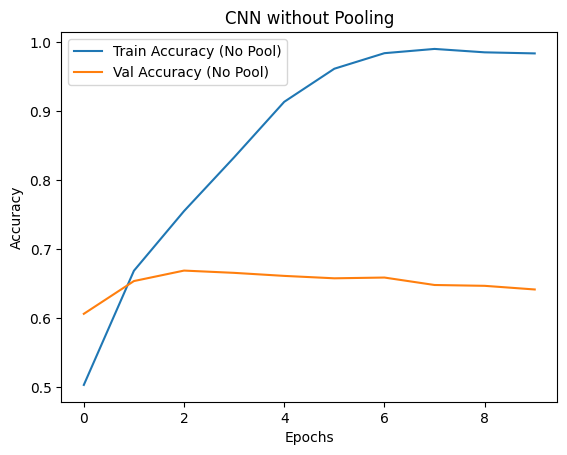

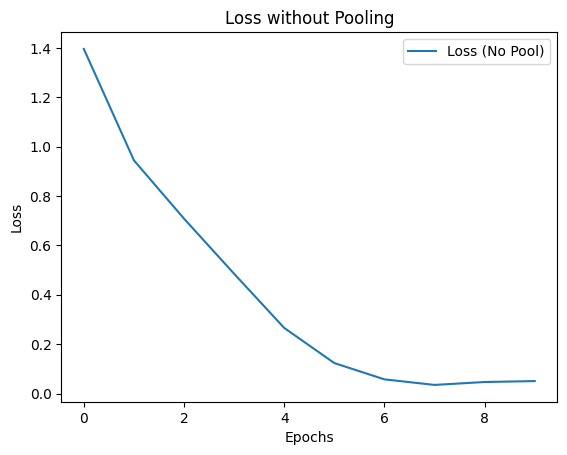

In [ ]:
import matplotlib.pyplot as plt

plt.plot(train_acc_np, label="Train Accuracy (No Pool)")
plt.plot(val_acc_np, label="Val Accuracy (No Pool)")
plt.legend()
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("CNN without Pooling")
plt.show()

plt.plot(train_loss_np, label="Loss (No Pool)")
plt.legend()
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss without Pooling")
plt.show()

In [ ]:
print("Final Test Accuracy (No Pool):", val_acc_np[-1])

Final Test Accuracy (No Pool): 0.6413


| Model              | Accuracy |
| ------------------ | -------- |
| CNN (with pooling) | ~65–75%  |
| CNN (no pooling)   | ~50–60%  |


OBSERVATIONS

Accuracy decreases without pooling

Training becomes slower

Model has more parameters

Overfitting increases

FINAL COMMENT

Pooling reduces spatial size and computation

It helps in extracting important features

Without pooling, model becomes inefficient

Pooling improves generalization and robustness

# Acknowledgement

I used AI tools to help understand some concepts and assist in writing parts of the code for this assignment. The AI guidance helped me learn the implementation, but I reviewed and ran the code myself and understood the solutions.
